# MLP (neural network) — PathSnap candidate classifier

Algorithm family: neural networks (a feed-forward multilayer perceptron).

This uses the same shared dataset, trip-level folds and metrics as every other model. The network is trained epoch by epoch with `pathsnap.modeling.EpochMLP`. That records real training and validation log loss after every epoch, which gives the loss curves the report asks for. It also early-stops on validation loss. The early-stopping validation set is 10% of the training trips; it never includes the CV validation fold or the student-test trips.

Outputs go to `models/mlp/`. Runtime is about 10–15 min with the settings below.

In [1]:
import os, sys, json, time
from pathlib import Path
# find the repo root (the folder that contains config.yaml) and make `pathsnap` importable
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook from inside the pathsnap-ml-hackathon repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap.dataset import FEATURES
from pathsnap import modeling as M
print("repo root:", ROOT)

repo root: C:\3rd year material\ML\Hackathon\pathsnap_preprocessing


## Settings

In [2]:
ROWS_PER_FOLD = 80_000      # 5 folds -> ~400k training rows (None = all rows, much slower)
PARAMS = dict(
    hidden_layer_sizes=(64, 32),
    alpha=1e-4,                # L2 regularisation
    learning_rate_init=1e-3,   # Adam
    batch_size=512,
    max_epochs=60,
    patience=5,                # early stopping on validation log loss
    es_trip_frac=0.1,
    seed=M.SEED,
)
OUT = ROOT / "models" / "mlp"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
tr, te, tr_pts, te_pts = M.load_data()
print(f"labelled train rows: {len(tr):,}  (positive rate {tr.label.mean():.3f}, trips {tr.trip_id.nunique()})")
print(f"rows used for FITTING: up to {ROWS_PER_FOLD or 'all'} per fold; validation always uses full folds")
print(f"student-test rows: {len(te):,}")

labelled train rows: 1,479,905  (positive rate 0.125, trips 80)
rows used for FITTING: up to 80000 per fold; validation always uses full folds
student-test rows: 169,408


## Model
Loss function: binary cross-entropy (log loss) plus L2 penalty `alpha`, optimised with Adam. The features are standardised, with the scaler fitted on the training rows only. Note: sklearn's MLP does not support per-sample weights, so `trip_weight` is not used for this model.

In [4]:
def make_model():
    return M.EpochMLP(**PARAMS)

def fit_fn(model, df):
    return model.fit_df(df)

## 5-fold group cross-validation (trip-level)

In [5]:
cv = M.cross_validate(make_model, fit_fn, tr, tr_pts, ROWS_PER_FOLD)
cv[["fold", "top1_accuracy", "train_top1", "f1_macro", "precision_macro", "recall_macro", "log_loss", "fit_seconds"]].round(4)

fold 0: val top1=0.8989  train top1=0.9290  f1_macro=0.9394  log_loss=0.0875  (20s)


fold 1: val top1=0.8395  train top1=0.9164  f1_macro=0.9088  log_loss=0.0910  (29s)


fold 2: val top1=0.8892  train top1=0.9070  f1_macro=0.9340  log_loss=0.0627  (32s)


fold 3: val top1=0.9278  train top1=0.8530  f1_macro=0.9542  log_loss=0.0539  (19s)


fold 4: val top1=0.8609  train top1=0.9081  f1_macro=0.9103  log_loss=0.0913  (26s)


,fold,top1_accuracy,train_top1,f1_macro,precision_macro,recall_macro,log_loss,fit_seconds
0,0,0.8989,0.9290,0.9394,0.9377,0.9411,0.0875,19.9949
1,1,0.8395,0.9164,0.9088,0.9216,0.8970,0.0910,29.2441
2,2,0.8892,0.9070,0.9340,0.9404,0.9279,0.0627,31.8954
3,3,0.9278,0.8530,0.9542,0.9527,0.9556,0.0539,18.7876
4,4,0.8609,0.9081,0.9103,0.9398,0.8857,0.0913,25.9148


CV Top-1     : 0.8833 ± 0.0342
CV macro F1  : 0.9293 ± 0.0195
CV log loss  : 0.0773
train Top-1  : 0.9027


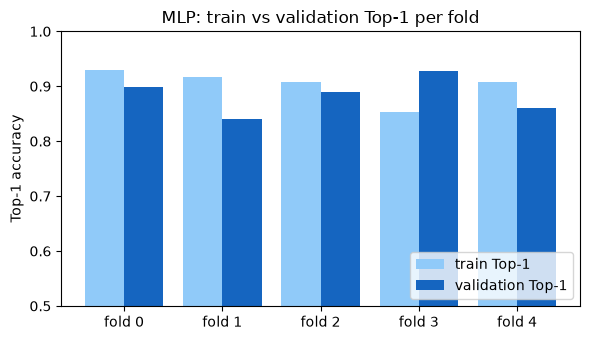

In [6]:
print("CV Top-1     : %.4f ± %.4f" % (cv.top1_accuracy.mean(), cv.top1_accuracy.std()))
print("CV macro F1  : %.4f ± %.4f" % (cv.f1_macro.mean(), cv.f1_macro.std()))
print("CV log loss  : %.4f" % cv.log_loss.mean())
print("train Top-1  : %.4f" % cv.train_top1.mean())
M.plot_cv_folds(cv, "MLP: train vs validation Top-1 per fold", OUT / "cv_folds.png")

## Final fit on all training rows → student-testing trips

In [7]:
model, scores, test, train_s, infer_ms = M.fit_and_test(make_model, fit_fn, tr, te, te_pts, ROWS_PER_FOLD)
print(f"train time: {train_s:.1f}s   epochs run: {len(model.history_)}   best epoch: {model.best_epoch_}")
print(f"inference: {infer_ms:.3f} ms per 1000 candidate rows")
pd.Series({k: v for k, v in test.items() if k != "confusion_matrix"}).to_frame("student_test")

train time: 25.0s   epochs run: 10   best epoch: 5
inference: 1.022 ms per 1000 candidate rows


,student_test
top1_accuracy,0.884075
top1_given_ref_in_candidates,0.884352
candidate_miss_rate,0.000314
accuracy,0.972191
precision_macro,0.933580
recall_macro,0.926538
f1_macro,0.930020
precision_pos,0.883976
recall_pos,0.867569
f1_pos,0.875696


## Training and validation loss per epoch (final model)

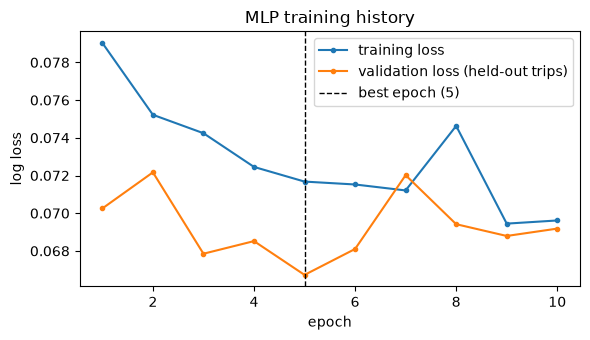

,epoch,train_loss,val_loss
0,1,0.0790,0.0703
1,2,0.0752,0.0722
2,3,0.0742,0.0679
3,4,0.0725,0.0685
4,5,0.0717,0.0667
5,6,0.0715,0.0681
6,7,0.0712,0.0720
7,8,0.0746,0.0694
8,9,0.0694,0.0688
9,10,0.0696,0.0692


In [8]:
M.plot_loss_history(model.history_, "MLP training history", OUT / "loss_curve.png", model.best_epoch_)
model.history_.to_csv(OUT / "training_history.csv", index=False)
model.history_.round(4)

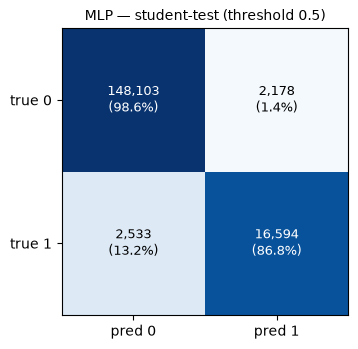

In [9]:
M.plot_confusion(test["confusion_matrix"], "MLP — student-test (threshold 0.5)", OUT / "confusion_matrix.png")

## Save results

In [10]:
res = M.save_run(OUT, "mlp", "Neural network", PARAMS, cv, test, train_s, infer_ms,
                 model=model, rows_per_fold=ROWS_PER_FOLD,
                 extra={"epochs_run": len(model.history_), "best_epoch": model.best_epoch_})
print(json.dumps({k: v for k, v in res.items() if k != "student_test"}, indent=1, default=str))

saved C:\3rd year material\ML\Hackathon\pathsnap_preprocessing\models\mlp\model.joblib (0.1 MB)
{
 "model": "mlp",
 "algorithm_family": "Neural network",
 "config": {
  "hidden_layer_sizes": [
   64,
   32
  ],
  "alpha": 0.0001,
  "learning_rate_init": 0.001,
  "batch_size": 512,
  "max_epochs": 60,
  "patience": 5,
  "es_trip_frac": 0.1,
  "seed": 42
 },
 "seed": 42,
 "train_rows_per_fold": 80000,
 "cv_top1_mean": 0.8832556878466253,
 "cv_top1_std": 0.034205504213630764,
 "cv_f1_macro_mean": 0.9293355278888283,
 "cv_f1_macro_std": 0.019508925926697736,
 "cv_log_loss_mean": 0.0772870648116354,
 "cv_train_top1_mean": 0.9027024044360259,
 "train_seconds": 25.04399569999987,
 "inference_ms_per_1000_rows": 1.0217439554300776,
 "epochs_run": 10,
 "best_epoch": 5
}


## Notes for the report (fill in from YOUR results above)
- Why an MLP suits PathSnap, and its strengths and limitations as observed.
- Hyperparameters and initial values: see `PARAMS`. Loss: binary cross-entropy + L2, optimiser Adam.
- Over- or underfitting: read it from the loss curve (where the validation loss stops falling) and from the gap between train and validation Top-1.